# 2 · A compartment model

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/albgirelli/Gonzo_viewer/blob/main/notebooks/02_compartment_model.ipynb)

The simplest possible model: treat each part of the system as a well-mixed box and let tracer move
between boxes at constant rates.

```
 spinal CSF  --k1-->  intracranial CSF  --k3-->  brain
                            |           <--k4--
                            k2
                            v
                         blood / out
```

$$S' = -k_1 S,\quad C' = k_1 S - (k_2 + k_3) C + k_4 B,\quad B' = k_3 C - k_4 B,\qquad S(0) = 250\,\mu\text{mol}.$$

We fit the four rates to the measured amounts of tracer in the intracranial CSF and in the brain.

In [1]:
# Setup: works both locally (inside the cloned repository) and on Google Colab.
from pathlib import Path
import subprocess

REPO_URL = "https://github.com/albgirelli/Gonzo_viewer"
if Path("../data/regions.csv").exists():
    DATA = Path("../data")
else:
    if not Path("Gonzo_viewer").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL], check=True)
    DATA = Path("Gonzo_viewer/data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

regions = pd.read_csv(DATA / "regions.csv").set_index("name")
hours = pd.read_csv(DATA / "sessions.csv").hours_after_injection.values
csf = regions.loc["All intracranial CSF"].filter(like="amount_umol").values.astype(float)
brain = regions.loc["All brain tissue"].filter(like="amount_umol").values.astype(float)
print("CSF  (µmol):", csf.round(1)); print("brain(µmol):", brain.round(1))

CSF  (µmol): [ 0.  61.7 65.7 40.1 21.2]
brain(µmol): [ 0.  11.7 44.1 40.2 26.7]


In [3]:
def model(t, y, k1, k2, k3, k4):
    S, C, B = y
    return [-k1 * S, k1 * S - (k2 + k3) * C + k4 * B, k3 * C - k4 * B]

def simulate(k, t_eval):
    sol = solve_ivp(model, (0, t_eval[-1]), [250, 0, 0], t_eval=t_eval, args=tuple(k), rtol=1e-8)
    return sol.y

def residuals(logk):
    y = simulate(np.exp(logk), hours)
    return np.concatenate([y[1] - csf, y[2] - brain])

fit = least_squares(residuals, np.log([0.05, 0.05, 0.05, 0.05]))
k = np.exp(fit.x)
for name, v in zip(["k1 spinal→cranial", "k2 CSF→out", "k3 CSF→brain", "k4 brain→CSF"], k):
    print(f"{name:20s} {v:.4f} /h   (half-life {np.log(2) / v:5.1f} h)")

k1 spinal→cranial    0.0815 /h   (half-life   8.5 h)
k2 CSF→out           0.0580 /h   (half-life  12.0 h)
k3 CSF→brain         0.0533 /h   (half-life  13.0 h)
k4 brain→CSF         0.0659 /h   (half-life  10.5 h)


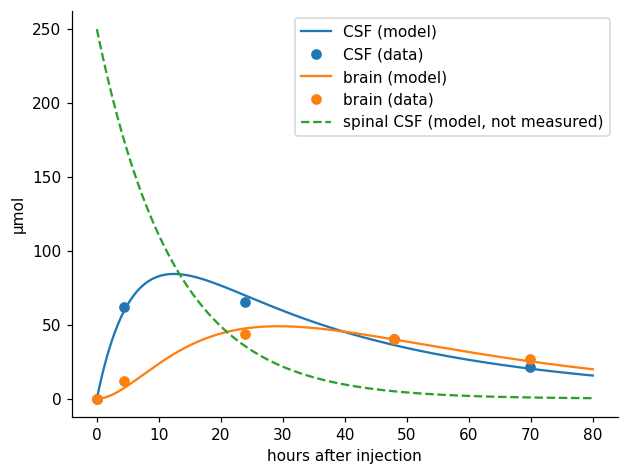

In [4]:
t = np.linspace(0, 80, 400)
y = simulate(k, t)
plt.plot(t, y[1], "C0", label="CSF (model)"); plt.plot(hours, csf, "C0o", label="CSF (data)")
plt.plot(t, y[2], "C1", label="brain (model)"); plt.plot(hours, brain, "C1o", label="brain (data)")
plt.plot(t, y[0], "C2--", label="spinal CSF (model, not measured)")
plt.xlabel("hours after injection"); plt.ylabel("µmol"); plt.legend();

## Questions to push on
* **Identifiability.** 4 parameters, 8 data points. Are the rates well determined? Try a profile likelihood, bootstrap, or a Bayesian fit (e.g. `emcee`).
* **Use the blood data** (`blood_plasma.csv`): add a blood compartment with renal clearance. Does it constrain the model?
* **More boxes.** Split the brain into cortex / white matter / deep grey matter (see `regions.csv`). Who feeds whom?
* **Predict.** Leave the 48 h scan out, fit, and predict it. How good is the prediction?
* **What if?** Halve the clearance rate (impaired clearance, e.g. ageing) or change the dose: what changes, and when?